# Homework 3.1 Solutions | Random Variables

*Homework is designed to both test your knowledge and challenge you to apply familiar concepts in new applications. Answer clearly and completely. You are welcomed and encouraged to work in groups so long as your work is your own. Submit your figures and answers to [Gradescope](https://www.gradescope.com).*

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Fix the random draws so the numbers match these solutions
np.random.seed(150)

## Q1. Working with a Normal Distribution

The wait times (in minutes) at a restaurant follow a normal distribution with mean $\mu = 12$ minutes and standard deviation $\sigma = 2.5$ minutes. Start each question with a rough sketch of your answer, then find the number using code. Two useful functions from Exercise 3.1: `stats.norm.cdf()` and `stats.norm.ppf()`.

In [2]:
# Population parameters
mu = 12
sigma = 2.5

a) What is the population mean ($\mu$) wait time? *(warm up question)*

The population mean wait time is $\mu = 12$ minutes (given directly in the problem).

b) What is the population variance of the wait time? *(warm up question)*

The population variance is $\sigma^2 = 2.5^2 = 6.25$ minutes$^2$.

c) What is the wait time that is longer than exactly 77 percent of wait times? *(use python)*

In [3]:
# 77th percentile
stats.norm.ppf(0.77, mu, sigma)

np.float64(13.847117122963034)

About 13.85 minutes. A wait of 13.85 minutes is longer than 77 percent of wait times.

d) What is the probability that a wait time will be greater than 10 minutes? *(use python)*

In [4]:
# P(X > 10) = 1 - P(X <= 10)
1 - stats.norm.cdf(10, mu, sigma)

np.float64(0.7881446014166034)

About 0.788, or a 78.8 percent chance.

e) What is the probability that the wait time will be between 10 and 14 minutes? *(use python)*

In [5]:
# P(10 < X < 14) = P(X < 14) - P(X < 10)
stats.norm.cdf(14, mu, sigma) - stats.norm.cdf(10, mu, sigma)

np.float64(0.5762892028332067)

About 0.576, or a 57.6 percent chance.

f) What is the probability that the wait time will be less than 7 or greater than 17 minutes? *(use python)*

In [6]:
# P(X < 7 or X > 17) = P(X < 7) + P(X > 17)
stats.norm.cdf(7, mu, sigma) + (1 - stats.norm.cdf(17, mu, sigma))

np.float64(0.0455002638963584)

About 0.0455, or a 4.6 percent chance. Both 7 and 17 are two standard deviations from the mean, so this is the familiar 5 percent in the two tails.

## Q2. Sample vs. Population

We know the restaurant's population parameters: $\mu = 12$ and $\sigma = 2.5$. But in the real world, we don't know the population. We only have a sample. In this question, you'll draw samples from the known population and see how well sample statistics approximate population parameters.

a) Use `np.random.normal(12, 2.5, 10)` to draw a sample of $n = 10$ wait times. Compute the sample mean and sample standard deviation (`np.std(sample, ddof=1)`). How do they compare to $\mu$ and $\sigma$?

In [7]:
sample_10 = np.random.normal(12, 2.5, 10)
print(f'Sample mean (n=10): {np.mean(sample_10):.3f}  (mu = {mu})')
print(f'Sample SD (n=10):   {np.std(sample_10, ddof=1):.3f}  (sigma = {sigma})')

Sample mean (n=10): 12.620  (mu = 12)
Sample SD (n=10):   1.772  (sigma = 2.5)


With this seed the sample mean is 12.62 and the sample SD is 1.77, so both miss $\mu = 12$ and $\sigma = 2.5$ by a noticeable amount. Your numbers will be different. With only 10 observations, the sample statistics are in the right neighborhood but can be off by quite a bit.

b) Repeat part a) for $n = 100$ and $n = 1000$. How do the sample statistics change as $n$ increases?

In [8]:
sample_100 = np.random.normal(12, 2.5, 100)
sample_1000 = np.random.normal(12, 2.5, 1000)

print(f'Sample mean (n=100):  {np.mean(sample_100):.3f}  (mu = {mu})')
print(f'Sample SD (n=100):    {np.std(sample_100, ddof=1):.3f}  (sigma = {sigma})')
print(f'Sample mean (n=1000): {np.mean(sample_1000):.3f}  (mu = {mu})')
print(f'Sample SD (n=1000):   {np.std(sample_1000, ddof=1):.3f}  (sigma = {sigma})')

Sample mean (n=100):  11.544  (mu = 12)
Sample SD (n=100):    2.626  (sigma = 2.5)
Sample mean (n=1000): 11.967  (mu = 12)
Sample SD (n=1000):   2.525  (sigma = 2.5)


As $n$ increases, the sample mean and sample standard deviation land closer to $\mu = 12$ and $\sigma = 2.5$. Any single sample can still miss, but larger samples miss by less.

c) Plot a histogram of your $n = 1000$ sample. On the same figure, overlay the population PDF using:

```python
x = np.linspace(4, 20, 200)
plt.plot(x, stats.norm.pdf(x, 12, 2.5))
```

How well does the sample histogram approximate the population?

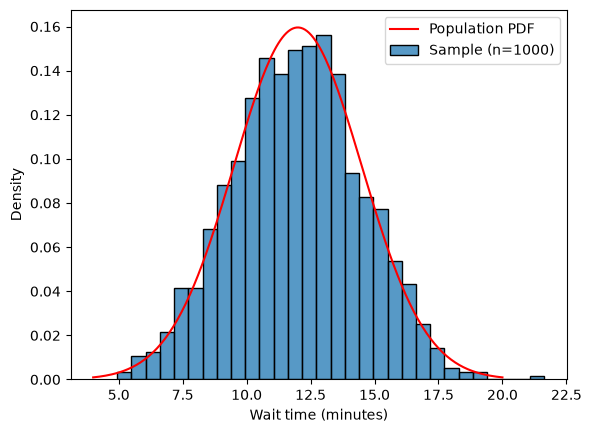

In [9]:
sns.histplot(sample_1000, stat='density', bins=30, label='Sample (n=1000)')
x = np.linspace(4, 20, 200)
plt.plot(x, stats.norm.pdf(x, 12, 2.5), color='red', label='Population PDF')
plt.xlabel('Wait time (minutes)')
plt.legend()
plt.show()

The histogram follows the population curve closely: same center, same spread, same bell shape. Individual bars wobble above and below the curve, but with 1,000 observations the sample is a good picture of the population. (Use `stat='density'` so the histogram is on the same scale as the PDF.)

d) In your own words, what is the relationship between a sample and a population? Why do larger samples give us more information about the population?

A sample is a set of observations drawn from the population. Its statistics (like the sample mean and standard deviation) are estimates of the population's parameters ($\mu$ and $\sigma$). A small sample can be thrown off by a few unusual draws. In a larger sample those unusual draws are balanced out by the many typical ones, so the sample's statistics and shape get closer to the population's.